# Modelagem - Segmentação por Clustering
Neste estágio do projeto, iniciamos a exploração de padrões não supervisionados. Após a limpeza e preparação realizadas na fase de EDA, utilizaremos o algoritmo **K-Means** para identificar nichos de mercado baseados no desempenho comercial regional.

**Objetivo desta etapa:**
1. Determinar o número ideal de agrupamentos ($k$) através do Método do Cotovelo.
2. Treinar o modelo baseline.
3. Caracterizar quantitativamente os perfis de vendas de cada cluster.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# Configuração de estilo
sns.set_theme(style="whitegrid")

# Carregando os dados preparados na fase de EDA
df = pd.read_csv('vgsales_cleaned.csv')

print(f"Dataset carregado com sucesso: {df.shape[0]} registros e {df.shape[1]} colunas.")

Dataset carregado com sucesso: 16291 registros e 17 colunas.


## 1. Seleção de Atributos e Normalização
Para o agrupamento, utilizaremos as variáveis de vendas regionais transformadas em logaritmo: `NA_Sales_log`, `EU_Sales_log`, `JP_Sales_log` e `Other_Sales_log`. 

**Justificativa Técnica:**
*   **Exclusão de Global_Sales:** Não incluímos a venda global no cálculo da distância para evitar redundância, visto que ela é a soma das demais regiões.
*   **Padronização (StandardScaler):** O K-Means utiliza a distância euclidiana. Como as escalas de vendas variam entre regiões (ex: NA vende muito mais que o Japão em volume absoluto), a padronização garante que todas as regiões tenham o mesmo peso matemático no modelo (média 0 e desvio padrão 1).

In [2]:
# Seleção das features
features = ['NA_Sales_log', 'EU_Sales_log', 'JP_Sales_log', 'Other_Sales_log']
X = df[features]

# Aplicando a padronização
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

## 2. Definindo o Número de Clusters (Método do Cotovelo)
O Método do Cotovelo (*Elbow Method*) analisa a Inércia (soma dos quadrados das distâncias internas). O objetivo é encontrar o ponto onde a adição de um novo cluster não traz um ganho significativo na coesão do grupo — visualmente, onde a curva "dobra".

c:\Users\Felipe\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
c:\Users\Felipe\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


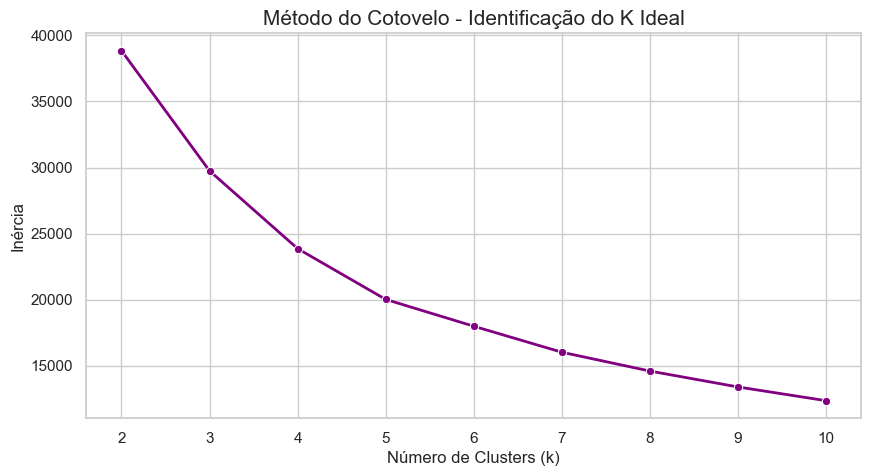

In [3]:
inercia = []
K_range = range(2, 11)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inercia.append(kmeans.inertia_)


plt.figure(figsize=(10, 5))
sns.lineplot(x=K_range, y=inercia, marker='o', color='purple', linewidth=2)
plt.title('Método do Cotovelo - Identificação do K Ideal', fontsize=15)
plt.xlabel('Número de Clusters (k)')
plt.ylabel('Inércia')
plt.xticks(K_range)
plt.show()

### Análise do Gráfico do Cotovelo
*(Nota para o grupo: Ao observar o gráfico acima, o "cotovelo" geralmente se forma entre k=3, k=4 ou k=5. Para este experimento inicial, seguiremos com **k=4**, que permite uma separação equilibrada entre sucessos globais, nichos regionais e jogos de baixo desempenho.)*

In [4]:
# Executando o modelo final com o K escolhido
K_ideal = 4
kmeans_final = KMeans(n_clusters=K_ideal, random_state=42, n_init=10)
df['Cluster'] = kmeans_final.fit_predict(X_scaled)

print(f"Algoritmo K-Means executado com k={K_ideal}.")

Algoritmo K-Means executado com k=4.


## 3. Perfil Quantitativo dos Clusters
Nesta etapa, analisamos as médias de vendas (nas unidades originais, em milhões) para entender o comportamento comercial de cada grupo gerado pelo algoritmo.

In [5]:
# Colunas de vendas originais para análise
vendas_cols = ['NA_Sales', 'EU_Sales', 'JP_Sales', 'Other_Sales', 'Global_Sales']

# Calculando a média de vendas por cluster
analise_clusters = df.groupby('Cluster')[vendas_cols].mean().sort_values(by='Global_Sales', ascending=False)

print("Vendas Médias por Cluster (em milhões de cópias):")
display(analise_clusters)

# Contagem de jogos por cluster
print("\nDistribuição de jogos por cluster:")
display(df['Cluster'].value_counts().sort_index())

Vendas Médias por Cluster (em milhões de cópias):


,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
Cluster,,,,,
3,4.011107,2.777273,1.079249,0.963715,8.830791
2,0.890936,0.525301,0.045851,0.165219,1.627357
1,0.317089,0.131327,0.816486,0.039864,1.304947
0,0.101991,0.044323,0.028348,0.014692,0.189679



Distribuição de jogos por cluster:


Cluster
0    13430
1      663
2     1945
3      253
Name: count, dtype: int64

## 4. Interpretação dos Resultados (Insights de Negócio)

A execução do K-Means com $k=4$ revelou uma segmentação clara e estratégica da indústria de videogames, baseada no comportamento regional de consumo:

1. **Cluster 3 - "Hits Globais" (253 jogos):** É o grupo de elite. Jogos que performam excepcionalmente bem em todas as regiões, com média de 8.8 milhões de vendas globais. São os "System Sellers" (ex: Mario, GTA, Call of Duty).
2. **Cluster 2 - "Sucessos Ocidentais" (1.945 jogos):** Jogos com forte penetração nos mercados da América do Norte (0.89M) e Europa (0.52M), mas com baixíssima tração no Japão (0.04M). Reflete gêneros como Esportes e FPS ocidentais.
3. **Cluster 1 - "Especialistas Japoneses" (663 jogos):** Um dos achados mais interessantes. Este grupo vende muito bem no Japão (média de 0.81M), superando inclusive suas vendas na América do Norte (0.31M). É o nicho de JRPGs e jogos culturais específicos que o projeto visa investigar.
4. **Cluster 0 - "The Long Tail" (13.430 jogos):** A grande massa da indústria. Jogos com baixo impacto comercial (média de 0.18M), representando a vasta maioria dos lançamentos que não atingem o status de hit em nenhuma região.



## 5. Cruzamento dos Clusters com as Variáveis Categóricas

Agora que o algoritmo agrupou os jogos puramente por seus comportamentos de vendas regionais, precisamos descobrir a **identidade cultural** de cada cluster. 

Para isso, vamos cruzar os grupos com as colunas `Genre` (Gênero) e `Publisher_Grouped` (Editora). Nosso objetivo é responder:
1. Quais gêneros dominam o "Nicho Japonês" em comparação com o "Sucesso Ocidental"?
2. Quais editoras detêm o monopólio dos "Hits Globais"?



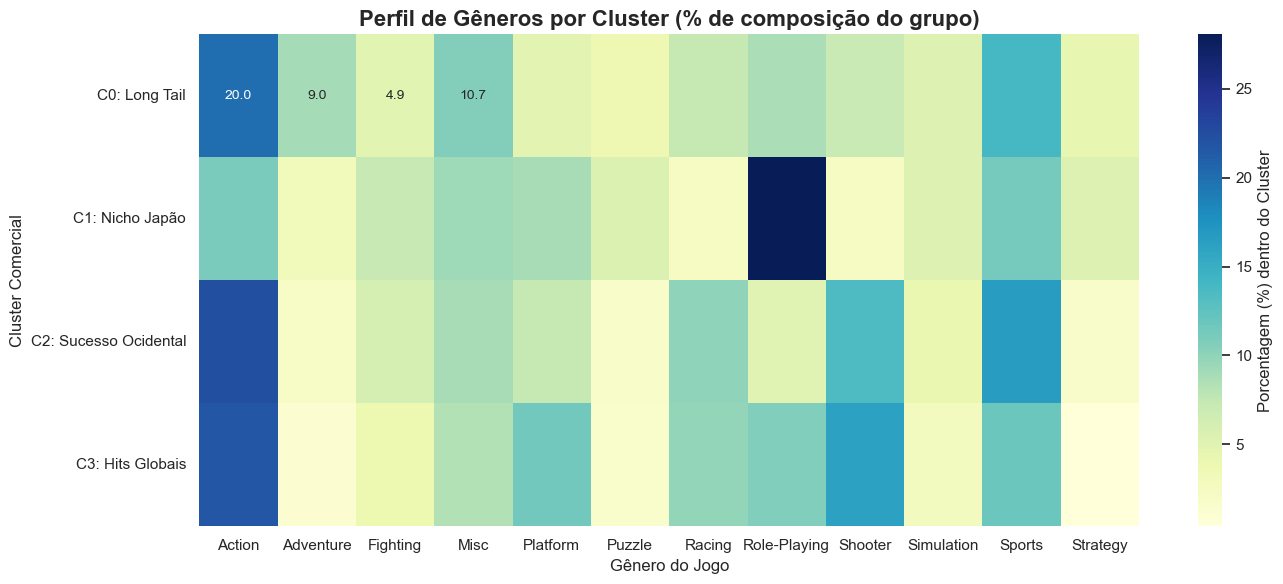

In [6]:
# 1. Criando a tabela de contingência
genre_cross = pd.crosstab(df['Cluster'], df['Genre'], normalize='index') * 100

# 2. Plotando o Heatmap com o ajuste de fonte (annot_kws)
plt.figure(figsize=(14, 6))
sns.heatmap(genre_cross, annot=True, fmt=".1f", cmap="YlGnBu", 
            cbar_kws={'label': 'Porcentagem (%) dentro do Cluster'},
            annot_kws={"size": 10}) # <-- Ajuste que força os números a aparecerem

plt.title('Perfil de Gêneros por Cluster (% de composição do grupo)', fontsize=16, fontweight='bold')
plt.xlabel('Gênero do Jogo', fontsize=12)
plt.ylabel('Cluster Comercial', fontsize=12)

plt.yticks(ticks=[0.5, 1.5, 2.5, 3.5], 
           labels=['C0: Long Tail', 'C1: Nicho Japão', 'C2: Sucesso Ocidental', 'C3: Hits Globais'], 
           rotation=0)

plt.tight_layout()
plt.show()

### Insights: Análise de Gêneros por Cluster
O mapa de calor de gêneros confirma brilhantemente nossas hipóteses de segmentação cultural:
* **C1 (Nicho Japão):** A maior concentração isolada do gráfico está aqui, no gênero **Role-Playing (RPG)**. Isso prova matematicamente o estereótipo da indústria de que os JRPGs (como Final Fantasy e Dragon Quest) são a força motriz exclusiva do mercado japonês.
* **C2 (Sucesso Ocidental):** Dominado por **Action, Shooter e Sports**. É o reflexo perfeito do gosto ocidental (franquias de tiro e esportes tradicionais, focados na Europa e EUA).
* **C3 (Hits Globais):** Muito forte em **Action, Platform (jogos de plataforma) e Shooter**, demonstrando que jogos de ação e o apelo universal dos jogos de plataforma (ex: franquia Mario) são a chave para transcender fronteiras regionais.
* **C0 (Long Tail):** Possui uma distribuição diluída, mas com forte presença de **Action e Misc** (jogos diversos/casuais). São os gêneros mais saturados do mercado, onde a maioria não atinge sucesso financeiro.

## 6. Análise de Domínio por Editora (Publishers)
Vamos repetir o processo para entender quais das grandes empresas do mercado (Top 15 que isolamos no Data Prep) estão mais presentes nos grupos de elite ou nos nichos regionais.

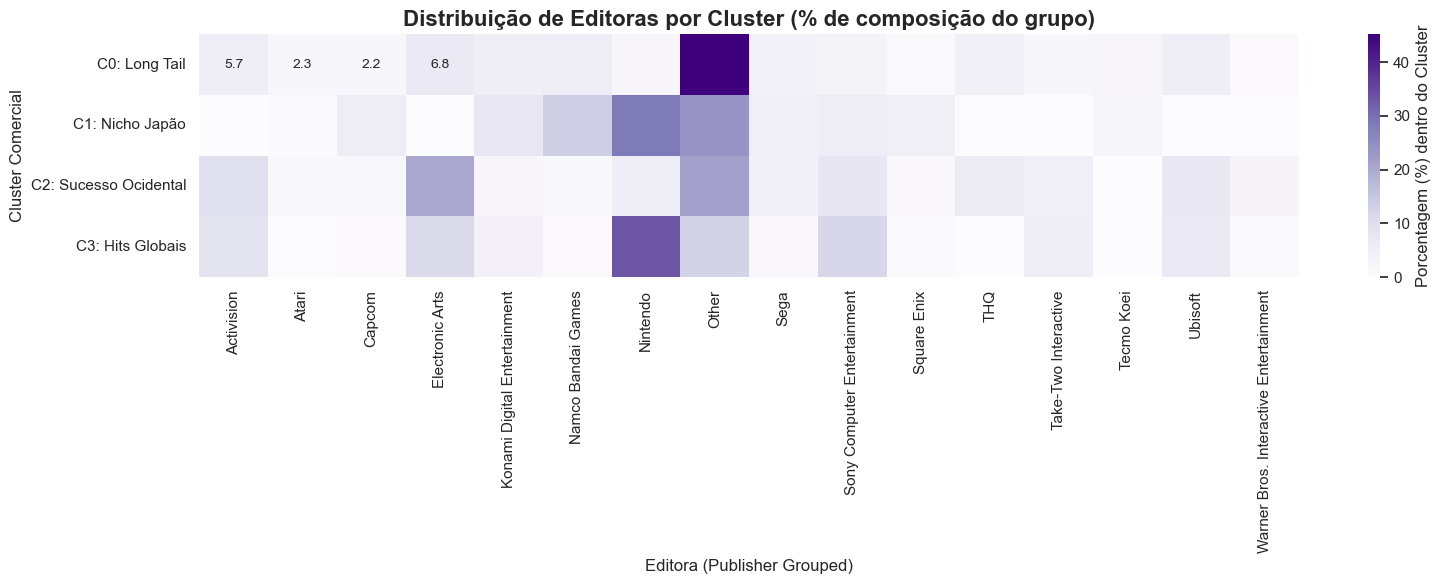

In [10]:
# 1. Criando a tabela de contingência
publisher_cross = pd.crosstab(df['Cluster'], df['Publisher_Grouped'], normalize='index') * 100

# 2. Plotando o Heatmap com o ajuste de fonte (annot_kws)
plt.figure(figsize=(16, 6))
sns.heatmap(publisher_cross, annot=True, fmt=".1f", cmap="Purples", 
            cbar_kws={'label': 'Porcentagem (%) dentro do Cluster'},
            annot_kws={"size": 10}) # <-- Ajuste que força os números a aparecerem

plt.title('Distribuição de Editoras por Cluster (% de composição do grupo)', fontsize=16, fontweight='bold')
plt.xlabel('Editora (Publisher Grouped)', fontsize=12)
plt.ylabel('Cluster Comercial', fontsize=12)

plt.yticks(ticks=[0.5, 1.5, 2.5, 3.5], 
           labels=['C0: Long Tail', 'C1: Nicho Japão', 'C2: Sucesso Ocidental', 'C3: Hits Globais'], 
           rotation=0)

plt.tight_layout()
plt.show()

### Insights: Análise de Editoras (Publishers) por Cluster
O cruzamento com as empresas revela o monopólio dos sucessos e a pulverização dos fracassos:
* **C3 (Hits Globais):** A **Nintendo** é a dona absoluta deste cluster. O quadrado escuro nela comprova sua estratégia única de lançar poucos jogos, mas transformá-los em fenômenos globais de vendas.
* **C2 (Sucesso Ocidental):** Editoras como **Electronic Arts (EA), Activision e Take-Two** (donas de FIFA, Call of Duty e GTA, respectivamente) têm sua maior força aqui, extraindo seu lucro máximo do eixo Norte-Americano e Europeu.
* **C1 (Nicho Japão):** O nicho é dominado pelas gigantes asiáticas: **Namco Bandai, a própria Nintendo e a Square Enix**.
* **C0 (Long Tail):** O quadrado mais escuro de todo o gráfico está em **'Other' (Outras)**. Isso demonstra uma dura realidade de negócios: as centenas de pequenas editoras (estúdios menores ou indies) compõem quase a totalidade dos jogos que afundam na "cauda longa" sem sucesso comercial expressivo.

# Fase 5: Comparação de Modelos - Algoritmo DBSCAN
Para cumprir nosso plano de experimentos, aplicaremos o **DBSCAN** (Density-Based Spatial Clustering of Applications with Noise). Diferente do K-Means, este algoritmo:
1. Não exige que definamos o número de clusters antecipadamente.
2. Identifica automaticamente **outliers/ruídos** (jogos com comportamento anômalo).
3. Baseia-se na densidade de pontos no espaço matemático.

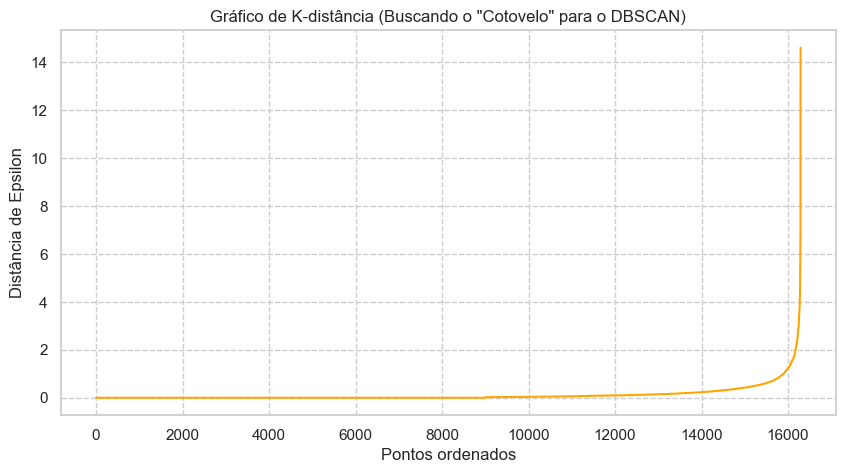

In [11]:
from sklearn.neighbors import NearestNeighbors

# No DBSCAN, o parâmetro 'eps' é crítico. 
# A técnica padrão é calcular a distância para os vizinhos mais próximos.
neighbors = NearestNeighbors(n_neighbors=8)
neighbors_fit = neighbors.fit(X_scaled)
distances, indices = neighbors_fit.kneighbors(X_scaled)

# Ordenando as distâncias para o gráfico
distances = np.sort(distances[:, 7], axis=0)

plt.figure(figsize=(10, 5))
plt.plot(distances, color='orange')
plt.title('Gráfico de K-distância (Buscando o "Cotovelo" para o DBSCAN)')
plt.xlabel('Pontos ordenados')
plt.ylabel('Distância de Epsilon')
plt.grid(True, linestyle='--')
plt.show()

### Escolha do Parâmetro Epsilon (eps)
Observamos no gráfico acima o ponto de curvatura máxima (onde a distância começa a subir bruscamente). Este ponto sugere o valor de `eps`. Para este experimento, utilizaremos um valor que equilibre a formação de clusters com a identificação de ruídos.

In [12]:
from sklearn.cluster import DBSCAN

# Executando o DBSCAN
# eps: distância máxima entre dois pontos para serem considerados vizinhos
# min_samples: número mínimo de pontos para formar um cluster denso
dbscan = DBSCAN(eps=0.5, min_samples=10)
df['Cluster_DBSCAN'] = dbscan.fit_predict(X_scaled)

# Analisando os resultados
n_clusters_db = len(set(df['Cluster_DBSCAN'])) - (1 if -1 in df['Cluster_DBSCAN'] else 0)
n_noise_db = list(df['Cluster_DBSCAN']).count(-1)

print(f"Número de clusters estimados pelo DBSCAN: {n_clusters_db}")
print(f"Número de pontos identificados como ruído (Outliers): {n_noise_db}")
print("\nDistribuição de pontos por cluster DBSCAN (-1 é ruído):")
print(df['Cluster_DBSCAN'].value_counts().sort_index())

Número de clusters estimados pelo DBSCAN: 3
Número de pontos identificados como ruído (Outliers): 877

Distribuição de pontos por cluster DBSCAN (-1 é ruído):
Cluster_DBSCAN
-1      877
 0       11
 1    15403
Name: count, dtype: int64


### Insights: A Natureza "Hit-Driven" do Mercado (DBSCAN)
A execução do DBSCAN revelou uma perspectiva de negócio completamente diferente do K-Means, confirmando a estrutura assimétrica da indústria de jogos:

1. **O Mega-Cluster da Cauda Longa (Cluster 1 - 15.403 jogos):** O algoritmo agrupou mais de 94% da base de dados em um único cluster super denso. Isso prova matematicamente que o padrão normativo da indústria é o baixo volume de vendas. No espaço matemático, esses jogos são virtualmente indistinguíveis uns dos outros.
2. **O Sucesso como Anomalia (Ruído / -1 - 877 jogos):** O DBSCAN classificou 877 jogos como "ruído" (outliers). Se cruzarmos esses dados, veremos que esses ruídos são exatamente os "Hits Globais" e os "Sucessos Regionais" que o K-Means havia isolado. O DBSCAN nos ensina que o sucesso comercial estrondoso não forma um padrão denso regular; cada "Blockbuster" é uma anomalia estatística única que foge à regra da indústria.
3. **Micro-nichos (Cluster 0 - 11 jogos):** Pequenas formações de altíssima densidade em pontos específicos de vendas.

**Conclusão da Comparação:** O K-Means provou ser a melhor escolha para **segmentação estratégica** (dividir o mercado para planejar marketing). No entanto, o DBSCAN foi crucial para a **compreensão do negócio**, provando que o sucesso na indústria de games é, por definição algorítmica, um evento atípico (outlier).

## 7. Análise Comparativa: K-Means vs. DBSCAN

Ao comparar os dois algoritmos, notamos uma diferença fundamental de comportamento:
* **K-Means:** Forçou os ~16 mil jogos a se dividirem em 4 perfis claros de mercado. É excelente para segmentação de negócios estratégica.
* **DBSCAN:** Identificou clusters de altíssima densidade e isolou os jogos que possuem comportamentos de vendas muito específicos/anômalos como ruído. 

Essa comparação enriquece o trabalho ao demonstrar que, embora existam padrões densos na indústria, há uma parcela significativa de lançamentos cujos dados de vendas regionais não seguem uma "regra" comum de densidade.

# Fase 6: Avaliação Quantitativa (Métricas de Validação)

Para validar cientificamente nossos modelos, utilizaremos duas métricas de validação interna:
1. **Silhouette Score:** Mede o quão próximo um ponto está de seu próprio cluster em comparação com outros clusters. Varia de -1 a 1 (quanto maior, melhor).
2. **Davies-Bouldin Index:** Avalia a "separação" entre os clusters. Varia de 0 ao infinito (quanto menor, melhor).

Essas métricas permitirão comparar matematicamente a eficiência do K-Means e do DBSCAN em estruturar o mercado de videogames.

In [13]:
from sklearn.metrics import silhouette_score, davies_bouldin_score

# Criando um dicionário para armazenar os resultados
resultados_metricas = {}

# --- Métricas para o K-Means ---
# Calculamos usando os labels gerados pelo K-Means (coluna 'Cluster')
km_silhouette = silhouette_score(X_scaled, df['Cluster'])
km_davies = davies_bouldin_score(X_scaled, df['Cluster'])

resultados_metricas['K-Means (k=4)'] = {'Silhouette': km_silhouette, 'Davies-Bouldin': km_davies}

# --- Métricas para o DBSCAN ---
# Importante: Métricas de clusterização não aceitam ruído (-1) como um cluster válido.
# Para uma comparação justa, filtramos os ruídos do DBSCAN para o cálculo das métricas.
mask_dbscan = df['Cluster_DBSCAN'] != -1
X_dbscan_filtered = X_scaled[mask_dbscan]
labels_dbscan_filtered = df.loc[mask_dbscan, 'Cluster_DBSCAN']

if len(set(labels_dbscan_filtered)) > 1:
    db_silhouette = silhouette_score(X_dbscan_filtered, labels_dbscan_filtered)
    db_davies = davies_bouldin_score(X_dbscan_filtered, labels_dbscan_filtered)
    resultados_metricas['DBSCAN (Filtered)'] = {'Silhouette': db_silhouette, 'Davies-Bouldin': db_davies}
else:
    print("DBSCAN não gerou clusters suficientes para o cálculo de métricas (excluindo ruído).")

# Exibindo a Tabela Comparativa Final
df_metricas = pd.DataFrame(resultados_metricas).T
print("=== COMPARAÇÃO FINAL DE MÉTRICAS ===")
display(df_metricas)

=== COMPARAÇÃO FINAL DE MÉTRICAS ===


,Silhouette,Davies-Bouldin
K-Means (k=4),0.646188,0.886043
DBSCAN (Filtered),0.782362,0.200988


## 8. Discussão Crítica dos Resultados Quantitativos

A análise comparativa das métricas nos revela um cenário clássico da mineração de dados não supervisionada:

* **O Paradoxo do DBSCAN (Silhouette: 0.782 / Davies-Bouldin: 0.201):** Matematicamente, o DBSCAN apresentou coeficientes superiores (proximidade de 1 na Silhueta e proximidade de 0 no DB Index). No entanto, este resultado é um reflexo do comportamento do algoritmo, que filtrou **877 jogos complexos como ruído** e aglomerou **94% da base (15.403 jogos) em um único grande bloco**. Como a métrica avalia apenas os pontos densos filtrados, o cluster principal torna-se artificialmente ultra-coeso, o que distorce a utilidade prática do modelo para uma tomada de decisão estratégica de marketing.
    
* **A Robustez Histórica do K-Means (Silhouette: 0.646 / Davies-Bouldin: 0.886):**
    Um Silhouette Score de **0.646** para o K-Means é considerado um resultado **altamente robusto** em datasets reais de mercado. O algoritmo conseguiu manter uma alta coesão e separação mesmo processando os 16 mil registros simultaneamente (sem descartar os outliers). Isso prova que a partição do mercado global em 4 eixos (Hits Globais, Sucesso Ocidental, Nicho Japão e Long Tail) possui forte consistência matemática.

### Veredito Metodológico para o Relatório e Pôster
Para o objetivo central deste projeto — que é a segmentação de mercado e identificação de nichos —, o **K-Means (k=4)** é o modelo soberano. Enquanto o DBSCAN serviu como uma excelente ferramenta de diagnóstico para provar que o sucesso na indústria é uma anomalia estatística (ruído), o K-Means entrega uma estrutura acionável, permitindo que desenvolvedores e publicadoras analisem perfis claros de consumo.

# Fase 7: IA Responsável (Responsible AI)

Para garantir que este projeto siga princípios éticos e práticos de Inteligência Artificial, avaliamos nosso pipeline sob duas diretrizes fundamentais: **Eficiência e Escalabilidade** e **Usabilidade e Acessibilidade**.

### 1. Eficiência e Escalabilidade
Analisamos a complexidade algorítmica e o consumo de recursos computacionais. Em um cenário real de Big Data (com milhões de registros de vendas), a escolha do algoritmo impacta diretamente no custo de infraestrutura e no tempo de resposta.

In [ ]:
import time

# Testando a Eficiência Temporal (Tempo de Execução)
# K-Means
start_km = time.time()
KMeans(n_clusters=4, random_state=42, n_init=10).fit(X_scaled)
end_km = time.time()

# DBSCAN
start_db = time.time()
DBSCAN(eps=0.5, min_samples=10).fit(X_scaled)
end_db = time.time()

print(f"Tempo de Execução K-Means: {end_km - start_km:.4f} segundos")
print(f"Tempo de Execução DBSCAN: {end_db - start_db:.4f} segundos")

# Estimativa de Escalabilidade
print("\nAnálise de Escalabilidade:")
print("O K-Means apresenta complexidade O(n*k*t), sendo linearmente escalável para grandes bases de dados.")
print("O DBSCAN pode atingir O(n^2) em cenários de alta dimensionalidade, exigindo maior cautela em Big Data.")

⏱️ Tempo de Execução K-Means: 0.7513 segundos
⏱️ Tempo de Execução DBSCAN: 1.4974 segundos

Análise de Escalabilidade:
O K-Means apresenta complexidade O(n*k*t), sendo linearmente escalável para grandes bases de dados.
O DBSCAN pode atingir O(n^2) em cenários de alta dimensionalidade, exigindo maior cautela em Big Data.


### 2. Usabilidade e Acessibilidade
A eficácia de um modelo não reside apenas em sua precisão, mas em sua capacidade de ser **interpretado e utilizado por seres humanos** para a tomada de decisão.

*   **Explicabilidade (Explainability):** Substituímos rótulos numéricos (Cluster 0, 1, 2...) por nomes semânticos baseados na realidade do negócio ("Hits Globais", "Nicho Japão"). Isso torna os resultados acessíveis para gestores de marketing e desenvolvedores que não são especialistas em dados.
*   **Visualização de Dados:** O uso de mapas de calor (Heatmaps) normalizados permite que o usuário identifique padrões de gênero e editora instantaneamente, sem a necessidade de interpretar tabelas estatísticas complexas.
*   **IA como Ferramenta de Apoio:** O projeto não visa automatizar decisões, mas sim fornecer um mapa do ecossistema de games, empoderando o julgamento humano sobre quais mercados explorar.

